# The good-enough call and the staffing note, for the festive window: which forecast goes to the plan, and how many packer shifts a week?

**Week 4, Friday, chapter 7, the case's third chapter.** It applies four of the day's
topics: trend and seasonality, read before modelling, for the windows a growth figure is
read against (concept notebook 01); naive, seasonal naive and drift baselines, for the
calendar copy (notebook 02); holding out, MAE and MAPE in the business's units, for a
hold-out that holds a festival and the misses priced (notebook 03); and the good-enough call
and the forecast note (notebook 04). On the chai stall (invented) those notebooks found that
a perfect forecast would order the same cans as the seasonal naive, so the owner stopped
improving and sent a four-line note.

**The ticket.** Flipkart, the Lucknow fulfilment centre (FC), the warehouse where orders are packed
and shipped. The centre has 104 weeks of outbound shipments, the weeks beginning Monday 30 September
2024 to Monday 21 September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025,
and falls on Sunday 8 November 2026; the festive sale runs in the third and second weeks before
Diwali's week. A packer packs about 120 shipments a shift, and a packer-shift is one packer working
one shift. The planner must book packer shifts for the eight weeks beginning 12 October to 30
November 2026, the festive window. A vendor's demand model promises the window 22 percent above the
same weeks last year; finance's rule is those weeks plus 4 percent: eighteen percentage points apart.
A late shipment costs Rs 25 (assumed, Rs 15 to 40). A spare shipment, planned for and never shipped,
leaves part of a packer-shift idle: Rs 650 a shift (assumed, Rs 500 to 800) over 120 shipments, Rs
5.42 a shipment. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

Chapter 6 scored every rule on thirteen hidden summer weeks: festival-aligned and finance's
rule tied at 6,615 a week, the house bot scored 9,831, the vendor 16,400. None of those
weeks held a festival, so the hold-out could not test the festive weeks the plan depends on.

**Who needs the answer.** The FC planner, who books the shifts, and the regional operations
head, who answers for late parcels in the festival's busiest weeks. A plan that puts the
peak in the wrong week pays for idle packers and late shipments in the same month.

**The questions on the way.** How did each rule do on 2025's festival? Which week does each
forecast put this year's peak in? How do the four forecasts compare with last year's two
windows? How many packer shifts a week, and how wrong could the plan be? Is a better
forecast worth having? What would the other plans cost?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
costs = pd.read_csv("../data/C2_W04_D05_costs_STUDENT.csv").set_index("item").rs
y = weekly.set_index("week_start").shipments
v = vendor.set_index("week_start").vendor_shipments
spare_rs = costs["idle_packer_shift"] / 120          # an idle shift's Rs 650 over 120 shipments: Rs 5.42
late_rs = costs["late_shipment"]                      # Rs 25 a late shipment
diwali = {2024: pd.Timestamp("2024-10-28"), 2025: pd.Timestamp("2025-10-20"), 2026: pd.Timestamp("2026-11-02")}

source = {}                                           # week -> the week festival-aligned copies for it
for d in pd.date_range(y.index[52], "2026-11-30", freq="7D"):   # every week with a year of weeks behind it
    source[d] = d - pd.Timedelta(weeks=52)            # outside the stretch: the same calendar week
    for year, w in diwali.items():
        gap = (d - w).days // 7                       # weeks from that year's Diwali week; -5 is five before
        if -5 <= gap <= 4 and year - 1 in diwali:
            source[d] = diwali[year - 1] + pd.Timedelta(weeks=gap)   # the same distance from last year's Diwali

print(f"a spare shipment costs Rs {spare_rs:.2f}; a late one Rs {late_rs}")
print(source[pd.Timestamp("2026-10-19")].date(), "is the source for the week of 19 Oct 2026")
check("the week of 19 Oct 2026 copies 6 Oct 2025", source[pd.Timestamp("2026-10-19")] == pd.Timestamp("2025-10-06"))

a spare shipment costs Rs 5.42; a late one Rs 25
2025-10-06 is the source for the week of 19 Oct 2026
PASS the week of 19 Oct 2026 copies 6 Oct 2025


## How did each rule do on 2025's festival?

The only festival the data can test the rules on is 2025's. A **back-test** stands at an
earlier date and forecasts what came next as if the later weeks were unknown: stand in the
week of 22 September 2025 and forecast the eight weeks from 29 September to 17 November
2025. Festival-aligned copies, from five weeks before Diwali's week to four after, the week
at the same distance from last year's Diwali. It adds no growth: in September 2025 the data
held one year, so no week had a twin a year earlier to measure growth on. The 4 percent
chapter 6 uses was measured later, on weeks up to June 2026; the cell runs that version too,
labelled, to show how much of the miss is growth. One more caution: this course set the
stretch, five weeks before Diwali's week to four after, to cover both festivals' busy weeks,
so even this back-test has seen the shape it tests, and the next festival is the clean test.

**Predict before you run.** By how many weeks does the house bot, the seasonal naive, miss
2025's peak?

a) none: same week last year knows the season
b) one week late
c) one week early
d) two weeks late

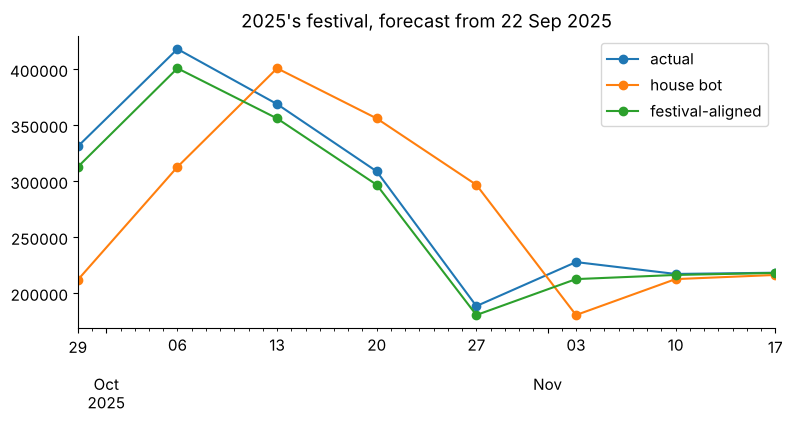

house bot: MAE 58,250; spare Rs 10.2 lakh, late Rs 69.6 lakh, total Rs 79.8 lakh
finance: MAE 60,488; spare Rs 13.0 lakh, late Rs 60.9 lakh, total Rs 73.9 lakh
festival-aligned: MAE 10,575; spare Rs 0.0 lakh, late Rs 21.1 lakh, total Rs 21.1 lakh
aligned, growth known later: MAE 4,034; spare Rs 1.0 lakh, late Rs 3.6 lakh, total Rs 4.6 lakh
overtime shifts: 1,638 in the week of 6 Oct 2025, 5 in the week of 24 Nov 2025
PASS the bot's peak is 13 Oct 2025, a week late
PASS festival-aligned peaks on 6 Oct 2025 with the actual


In [2]:
weeks25 = pd.date_range("2025-09-29", periods=8, freq="7D")        # 29 Sep to 17 Nov 2025
back = pd.DataFrame({
    "actual": y.loc[weeks25],
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks25],
    "finance": [round(y[d - pd.Timedelta(weeks=52)] * 1.04) for d in weeks25],
    "festival-aligned": [y[source[d]] for d in weeks25],                         # no growth: none could be measured yet
    "aligned, growth known later": [round(y[source[d]] * 1.04) for d in weeks25],  # the 4 percent from weeks up to June 2026
}, index=weeks25)
back[["actual", "house bot", "festival-aligned"]].plot(marker="o", title="2025's festival, forecast from 22 Sep 2025")
plt.show()
for rule in ["house bot", "finance", "festival-aligned", "aligned, growth known later"]:
    miss = back[rule] - back.actual                                  # positive: too high
    spare = miss[miss > 0].sum() * spare_rs
    late = -miss[miss < 0].sum() * late_rs
    print(f"{rule}: MAE {miss.abs().mean():,.0f}; spare Rs {spare / 100_000:.1f} lakh, "
          f"late Rs {late / 100_000:.1f} lakh, total Rs {(spare + late) / 100_000:.1f} lakh")
overtime = weekly.set_index("week_start").overtime_shifts
print(f"overtime shifts: {overtime['2025-10-06']:,} in the week of 6 Oct 2025, {overtime['2025-11-24']} in the week of 24 Nov 2025")
check("the bot's peak is 13 Oct 2025, a week late", back["house bot"].idxmax() == pd.Timestamp("2025-10-13"))
check("festival-aligned peaks on 6 Oct 2025 with the actual", back["festival-aligned"].idxmax() == back.actual.idxmax())

**What happened.** The answer is b. The house bot put 2024's peak on 13 October 2025, a
week late: MAE 58,250 and Rs 79.8 lakh of misses, Rs 69.6 lakh of it late shipments in the
weeks where 2025's rush came before the copy expected it. Finance's rule, the same copy plus
4 percent, missed by 60,488 a week. Festival-aligned, run as a planner in September 2025
could run it, missed by 10,575 a week and Rs 21.1 lakh, every week too low by about the
growth it could not yet measure, and it put the peak in the right week; with the growth
measured later it would have missed by 4,034. One festival is a thin test, so the plan
treats this as evidence about placement, never as a precise error.

## Which week does each forecast put this year's peak in?

Diwali 2026 falls on Sunday 8 November, so its week begins 2 November, and the sale, and
with it the peak, should come two weeks before, in the week of 19 October.

**Predict before you run.** Which week does the house bot's copy of 2025 make the busiest
week of the festive season?

a) 5 October 2026
b) 19 October 2026
c) 26 October 2026
d) 2 November 2026

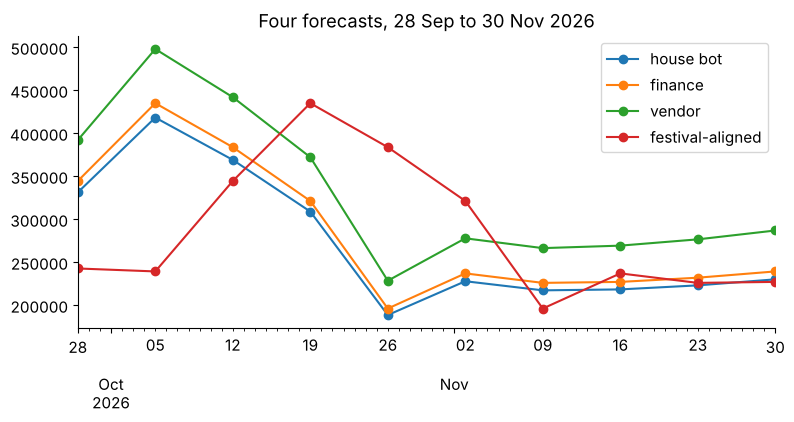

house bot           2026-10-05
finance             2026-10-05
vendor              2026-10-05
festival-aligned    2026-10-19
PASS the bot's busiest week is 5 Oct 2026
PASS festival-aligned's busiest week is 19 Oct 2026


In [3]:
weeks26 = pd.date_range("2026-09-28", periods=10, freq="7D")        # 28 Sep to 30 Nov 2026
ahead = pd.DataFrame({
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks26],
    "finance": [round(y[d - pd.Timedelta(weeks=52)] * 1.04) for d in weeks26],
    "vendor": v.loc[weeks26].values,
    "festival-aligned": [round(y[source[d]] * 1.04) for d in weeks26],
}, index=weeks26)
ahead.plot(marker="o", title="Four forecasts, 28 Sep to 30 Nov 2026")
plt.show()
print(ahead.idxmax().dt.date.to_string())
check("the bot's busiest week is 5 Oct 2026", ahead["house bot"].idxmax() == pd.Timestamp("2026-10-05"))
check("festival-aligned's busiest week is 19 Oct 2026", ahead["festival-aligned"].idxmax() == pd.Timestamp("2026-10-19"))

**What happened.** The answer is a. The house bot, finance's rule and the vendor all make 5
October 2026 the busiest week, because each copies 2025's calendar weeks; festival-aligned
puts it on 19 October, two weeks before Diwali's week. The window the planner books starts
a week after 5 October, so inside it the calendar copies book the most for 12 October
(369,000 from the house bot) and far too little for 19 and 26 October (308,900 and 188,600),
when festival-aligned expects 434,928 and 383,760. The vendor's model never knew the
festival moved.

## How do the four forecasts compare with last year's window?

"Last year's window" has two readings, as notebook 01 read the stall's growth (invented)
only against the same point a year apart. The same calendar weeks, 13 October to 1 December 2025, hold
only the tail of 2025's festival. The same weeks counted from Diwali, 29 September to 17
November 2025, hold all of it.

**Predict before you run.** Finance's eight weeks sit 4 percent above the same calendar
weeks of 2025. Where do they sit against 2025's weeks counted from Diwali?

a) 4 percent above, the same as on the calendar weeks
b) between 0 and 4 percent above
c) below them

In [4]:
window = weeks26[2:]                                    # 12 Oct to 30 Nov 2026, the weeks to book
calendar_2025 = y.loc[window - pd.Timedelta(weeks=52)].sum()
festival_2025 = y.loc[[source[d] for d in window]].sum()
totals = ahead.loc[window].sum()
compare = pd.DataFrame({"eight weeks": totals.map("{:,}".format),
                        "vs same calendar weeks": (totals / calendar_2025 - 1).map("{:+.1%}".format),
                        "vs same weeks from Diwali": (totals / festival_2025 - 1).map("{:+.1%}".format)})
print(f"2025, same calendar weeks: {calendar_2025:,}   2025, same weeks from Diwali: {festival_2025:,}")
print(compare.to_string())
print(f"finance below festival-aligned: {totals['festival-aligned'] - totals['finance']:,} shipments")
check("finance is plus 4 percent on the calendar window", round(totals["finance"] / calendar_2025 - 1, 3) == 0.04)
check("the vendor is plus 22 percent on the calendar window", round(totals["vendor"] / calendar_2025 - 1, 3) == 0.22)
check("finance sits below festival-aligned", totals["finance"] < totals["festival-aligned"])

2025, same calendar weeks: 1,983,300   2025, same weeks from Diwali: 2,279,500
                 eight weeks vs same calendar weeks vs same weeks from Diwali
house bot          1,983,300                  +0.0%                    -13.0%
finance            2,062,632                  +4.0%                     -9.5%
vendor             2,419,500                 +22.0%                     +6.1%
festival-aligned   2,370,680                 +19.5%                     +4.0%
finance below festival-aligned: 308,048 shipments
PASS finance is plus 4 percent on the calendar window
PASS the vendor is plus 22 percent on the calendar window
PASS finance sits below festival-aligned


**What happened.** The answer is c. Against the calendar weeks, festival-aligned reads 19.5
percent above last year, close to the vendor's 22.0, because 2026's peak weeks fall inside
the window and 2025's fell before it. Against the weeks counted from Diwali it reads 4.0
percent. Finance's plus 4 is plus 4 only on the calendar window: against last year's
festival weeks it sits 9.5 percent below, and against festival-aligned's forecast it is
308,048 shipments short, on the costly side. The vendor's total sits 2.1 percent above
festival-aligned, with its busiest week on 5 October.

## How many packer shifts does each week need, and how wrong could the plan be?

The plan books festival-aligned's forecast: each week's shipments over 120 a shift, rounded
up, since a shipment that does not fill a shift still needs one. The error bar has two
parts. Its typical miss is chapter 6's MAE in the business's unit, priced each way, as
notebook 03 priced the stall's misses (invented). Its range is how far the hidden weeks'
misses ran either way, applied to the plan's busiest week.

            festival-aligned forecast  packer shifts
2026-10-12                     344448           2871
2026-10-19                     434928           3625
2026-10-26                     383760           3198
2026-11-02                     321256           2678
2026-11-09                     196144           1635
2026-11-16                     237016           1976
2026-11-23                     225992           1884
2026-11-30                     227136           1893
Book 19,760 packer shifts for 12 October to 30 November, peaking at 3,625 in the week of 19 October.
The typical miss: 6,615 shipments a week, about 55 shifts; about Rs 35,800 of idle shifts a week if it runs that far high, Rs 1.65 lakh of late shipments if that far low.
The range: the hidden weeks ran from 5.9% below the forecast to 7.8% above; for the week of 19 October that is 3,413 to 3,906 shifts against 3,625 booked, about Rs 1.4 lakh of idle shifts at one end and Rs 8.4 lakh of late shipments at the other.


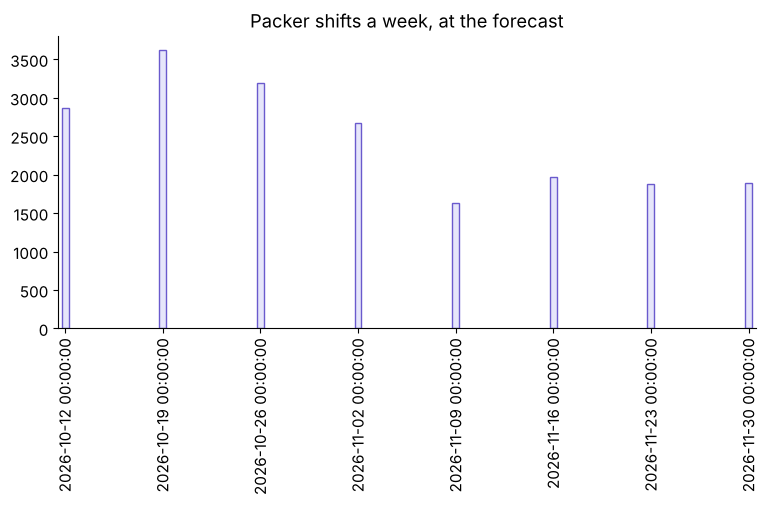

PASS the plan books 19,760 packer shifts
PASS the busiest week of the plan is 19 Oct 2026


In [5]:
forecast = ahead.loc[window, "festival-aligned"]
shifts = (forecast / 120).apply(math.ceil)                       # whole shifts, rounded up
staffing = pd.DataFrame({"festival-aligned forecast": forecast, "packer shifts": shifts})
print(staffing.to_string())
error_bar = 6615                                                 # chapter 6's MAE, shipments a week
print(f"Book {shifts.sum():,} packer shifts for 12 October to 30 November, peaking at {shifts.max():,} "
      f"in the week of {shifts.idxmax():%d %B}.")
print(f"The typical miss: {error_bar:,} shipments a week, about {error_bar / 120:.0f} shifts; about "
      f"Rs {round(error_bar * spare_rs, -2):,.0f} of idle shifts a week if it runs that far high, "
      f"Rs {error_bar * late_rs / 100_000:.2f} lakh of late shipments if that far low.")
hold = y.iloc[91:]                                               # chapter 6's thirteen hidden weeks
fa_hold = (y.shift(52).loc[hold.index] * 1.04).round()           # festival-aligned on them
share = (hold - fa_hold) / fa_hold                               # each week's miss as a share of the forecast
peak = forecast["2026-10-19"]
low, high = peak * (1 + share.min()), peak * (1 + share.max())
print(f"The range: the hidden weeks ran from {-share.min():.1%} below the forecast to {share.max():.1%} above; "
      f"for the week of 19 October that is {math.ceil(low / 120):,} to {math.ceil(high / 120):,} shifts against "
      f"{shifts['2026-10-19']:,} booked, about Rs {(peak - low) * spare_rs / 100_000:.1f} lakh of idle shifts at "
      f"one end and Rs {(high - peak) * late_rs / 100_000:.1f} lakh of late shipments at the other.")
staffing["packer shifts"].plot.bar(color="lavender", edgecolor="slateblue", title="Packer shifts a week, at the forecast")
plt.show()
check("the plan books 19,760 packer shifts", shifts.sum() == 19760)
check("the busiest week of the plan is 19 Oct 2026", shifts.idxmax() == pd.Timestamp("2026-10-19"))

**What happened.** The plan books 19,760 packer shifts over the eight weeks, peaking at
3,625 in the week of 19 October. Its typical miss is 6,615 shipments a week, about 55
shifts, 3.0 percent of an ordinary summer week; the festive weeks are bigger and may miss by
more. Its range at the peak runs from 3,413 to 3,906 shifts. A late shipment costs 4.6 times
a spare one, so the same miss is dear when the plan runs short and cheap when it runs high,
which is why the note prices both. The plan books the forecast itself; a margin, if the
planner adds one, goes above it, since short is the dear side, and how far is the plan
quantile, a step beyond today's five topics.

## Is a better forecast worth having?

Good enough is a claim about the decision, as the stall's cans (invented) showed in notebook
04: a better forecast is worth having only when what it changes in the order is worth more
than the work of getting it. At the stall it changed no can. Here a shift is 120 shipments,
small beside a typical miss of 6,615 a week, so any better forecast changes some shifts, and
the question becomes one of rupees.

In [6]:
gaps = {"house bot": 9831 - 6615, "vendor": 16400 - 6615}                     # chapter 6's MAEs: extra miss a week
print("extra miss against festival-aligned, shifts' worth a week:", {k: round(g / 120) for k, g in gaps.items()})
better = 100                                                                   # a rule whose MAE is 100 lower
week_low, week_high = better * spare_rs, better * late_rs                      # those 100 shipments spare, or late
print(f"a rule whose MAE is {better} lower saves Rs {week_low:,.0f} to Rs {week_high:,.0f} a week, "
      f"Rs {round(8 * week_low, -2):,.0f} to Rs {8 * week_high:,.0f} over the eight weeks")
check("the house bot and the vendor each miss by more than a shift a week more", min(gaps.values()) > 120)
check("a rule 100 better saves at most Rs 20,000 over the eight weeks", 8 * week_high == 20_000)

extra miss against festival-aligned, shifts' worth a week: {'house bot': 27, 'vendor': 82}
a rule whose MAE is 100 lower saves Rs 542 to Rs 2,500 a week, Rs 4,300 to Rs 20,000 over the eight weeks
PASS the house bot and the vendor each miss by more than a shift a week more
PASS a rule 100 better saves at most Rs 20,000 over the eight weeks


**What happened.** Festival-aligned goes to the plan. The house bot misses by 27 more
shifts' worth a week and the vendor by 82: gaps that cost real money every week. A rule
whose MAE is 100 shipments lower would save Rs 542 to Rs 2,500 a week, Rs 4,300 to Rs
20,000 over the eight weeks, so it is worth building only if it costs less than that to
build and run, and only after it wins on a test that did not choose it: a rolling origin
and the next festival.

## What would the other plans cost if demand follows the festival-aligned forecast?

A scenario, never a measurement: if festival-aligned is right about where the rush falls,
what does booking by each other forecast cost? Each plan is priced against festival-aligned's
weeks, Rs 5.42 for every spare shipment and Rs 25 for every shipment short. The 2025
back-test is the evidence that festival-aligned places the rush well; this table prices
being wrong about it.

In [7]:
booked = {"house bot": ahead.loc[window, "house bot"], "finance": ahead.loc[window, "finance"],
          "vendor": ahead.loc[window, "vendor"]}
scenario = {}
for name, b in booked.items():
    gap = b - forecast                                         # positive: spare capacity
    scenario[name] = (gap[gap > 0].sum() * spare_rs - gap[gap < 0].sum() * late_rs) / 100_000
    print(f"{name}: Rs {scenario[name]:.1f} lakh")
check("every calendar-copied plan costs more than Rs 80 lakh in this scenario", min(scenario.values()) > 80)

house bot: Rs 111.6 lakh
finance: Rs 103.6 lakh
vendor: Rs 82.2 lakh
PASS every calendar-copied plan costs more than Rs 80 lakh in this scenario


**What happened.** If demand follows festival-aligned, the house bot's weeks cost Rs 111.6
lakh, finance's Rs 103.6 lakh and the vendor's Rs 82.2 lakh, mostly late shipments in the
weeks of 19 October to 2 November.

## What can two years of weeks not tell us?

- **The festival moves, and the sale moves with it.** Tested on one festival only: the 2025
  back-test.
- **Two years hold only two festivals,** so the festival's shape rests on two examples; no
  check inside the data closes that.
- **The hidden weeks hold no festive week,** so their 6,615 is an ordinary-week error; on
  2025's festival festival-aligned missed by 10,575 a week with no growth added, one
  festival's evidence.
- **The stretch around Diwali** was set by this course to cover both festivals' busy weeks,
  so the 2025 back-test has seen the shape it tests; the next festival is the clean test.
- **Capacity caps the peak.** Overtime reached 1,638 shifts in the week of 6 October 2025
  against 5 in the week of 24 November 2025, as the back-test cell printed, so peak demand
  may have run above what shipped.
- **The 4 percent growth** is two years' evidence; a third year could move it.
- **The vendor's model has never forecast a Lucknow festival it had not seen,** so its
  festive numbers are an untested assumption.

## Depth, beyond the row: how far above the forecast should the plan sit?

This section goes beyond the row, that is, beyond Friday's five topics. It is the plan
quantile, which the fallback session teaches; the plan above books the forecast itself. It
opens on the chai stall (invented): a cup short costs Rs 12 and a cup unsold Rs 6, so one
more cup of milk pays off whenever the stall would sell it on more than one day in three,
and the owner should cover demand on two days in three, 12 over 12 plus 6.

**Predict before you run.** At Flipkart a late shipment costs Rs 25 and a spare one Rs
5.42. Where should the plan sit?

a) at the forecast, covering demand in about half the weeks
b) above the forecast, covering demand in about four weeks of five
c) far enough above to cover every week
d) below the forecast, since spare shipments waste money

The cell below works out the share of weeks the plan should cover from the two costs, then
reads that point off festival-aligned's own misses on chapter 6's hidden weeks. Here the
miss is measured the other way round: how far demand came **above** the forecast, as a
share of it, so a positive number is a week the forecast was too low.

In [8]:
hold = y.iloc[91:]                                              # chapter 6's thirteen hidden weeks
fa_hold = (y.shift(52).loc[hold.index] * 1.04).round()          # festival-aligned on them
above = (hold - fa_hold) / fa_hold                              # demand above the forecast, as a share
print("demand above the forecast, percent, smallest first:")
print((above * 100).round(1).sort_values().to_list())
q = late_rs / (late_rs + spare_rs)                              # the share of weeks to cover
cushion = round(above.quantile(q), 3)                           # 0.82 of the way along the sorted thirteen
covered = (above <= cushion).sum()
print(f"cover {q:.2f} of weeks: raise the forecast by {cushion:.1%}, which covers {covered} of the 13 weeks")
raised = fa_hold * (1 + cushion)
gap = raised - hold                                             # positive: spare
raised_cost = (gap[gap > 0].sum() * spare_rs - gap[gap < 0].sum() * late_rs) / 100_000
print(f"raised by {cushion:.1%}, these weeks' misses cost Rs {raised_cost:.1f} lakh, read from the same weeks")
check("the plan share is about 0.82", round(q, 2) == 0.82)
check("the cushion sits between the 10th and 11th sorted weeks",
      sorted(above)[9] <= cushion <= sorted(above)[10])
own = {}
for name, col in [("festival-aligned", fa_hold), ("house bot", y.shift(52).loc[hold.index]), ("vendor", v.loc[hold.index])]:
    share_up = (hold - col) / col                                 # each forecast's own misses, as a share
    gap = (col * (1 + round(share_up.quantile(q), 3))).round() - hold       # moved to its own 0.82 point
    own[name] = round(float(gap[gap > 0].sum() * spare_rs - gap[gap < 0].sum() * late_rs) / 100_000, 1)
print("each forecast at its own 0.82 point, misses priced on the same weeks, Rs lakh:", own)

demand above the forecast, percent, smallest first:
[-5.9, -5.1, -3.0, -2.1, -1.8, -0.4, 0.4, 1.5, 1.7, 2.1, 2.7, 5.4, 7.8]
cover 0.82 of weeks: raise the forecast by 2.6%, which covers 10 of the 13 weeks
raised by 2.6%, these weeks' misses cost Rs 8.8 lakh, read from the same weeks
PASS the plan share is about 0.82
PASS the cushion sits between the 10th and 11th sorted weeks
each forecast at its own 0.82 point, misses priced on the same weeks, Rs lakh: {'festival-aligned': 8.8, 'house bot': 8.8, 'vendor': 10.0}


**What happened.** The answer is b. Raise the plan by one shipment and two things can happen.
If demand turns out higher, that shipment is no longer late, which saves Rs 25. If demand
turns out lower, it is a spare shipment, which wastes Rs 5.42. Picture 100 weeks. If demand
beats the plan in 18 of them, one more shipment of plan saves 18 x Rs 25 = Rs 450 and wastes
82 x Rs 5.42 = Rs 444: about even, so stop there. That is the rule, called the newsvendor
rule after a seller deciding how many papers to stock: plan so that demand is covered in
this share of weeks.

$$\text{share covered} = \frac{\text{late cost}}{\text{late cost} + \text{spare cost}} = \frac{25}{25 + 5.42} \approx 0.82$$

Sorted, the thirteen weeks run from 5.9 percent below the forecast to
7.8 percent above. The 0.82 point sits between the 10th week, 2.1 percent, and the 11th,
2.7 percent; `quantile` reads it 0.82 of the way along the list, at 2.6 percent. The raised
forecast covers 10 of the 13 weeks, and the 11th misses by a hair. With thirteen weeks the
point is loose: `quantile`'s 2.6 percent is one reading, and the cost curve below bottoms
out at the 11th sorted week, 2.7 percent (2.8 on its grid of steps). It also shows why the
reading matters little: the busiest week costs about Rs 1.4 lakh anywhere from 2 to 4
percent above the forecast, against Rs 2.1 lakh booked at the forecast itself.

For one possible demand the week costs the spare shipments, `max(0, plan_level - demand)`,
at Rs 5.42, plus the late ones, `max(0, demand - plan_level)`, at Rs 25; at most one of the
two is above zero.

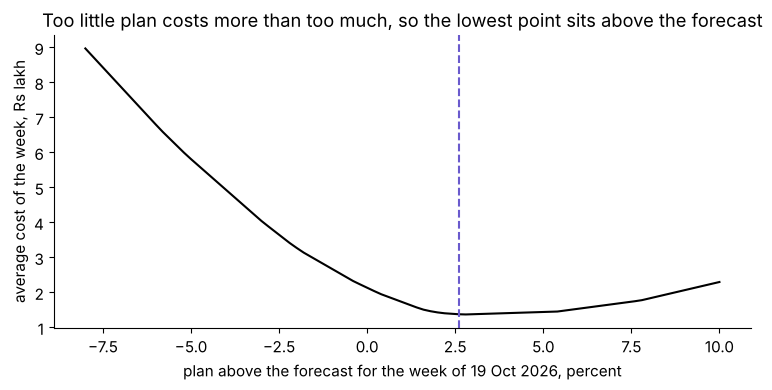

the lowest cost sits 2.8% above the forecast; the plan takes 2.6%
raised, the plan books 20,275 shifts, 515 more than the 19,760 at the forecast, and 3,719 in the week of 19 October
PASS the cheapest plan sits above the forecast
PASS the raised plan books 20,275 shifts
raised plan against the vendor: 12,819 shipments apart over the eight weeks, 291,183 more across 19 October to 2 November; 3,082 more shifts than finance's rule


In [9]:
base = forecast["2026-10-19"]                                 # the plan's busiest week
levels = [i / 1000 for i in range(-80, 101, 2)]               # 8 percent below to 10 percent above
cost_at = []
for g in levels:                                              # each way the plan could be raised
    plan_level = base * (1 + g)
    total = 0
    for a in above:                                           # each past miss, as a possible demand
        demand = base * (1 + a)
        total += max(0, plan_level - demand) * spare_rs + max(0, demand - plan_level) * late_rs
    cost_at.append(total / len(above) / 100_000)              # the week's average cost, Rs lakh
plt.plot([g * 100 for g in levels], cost_at, color="black")
plt.axvline(cushion * 100, ls="--", color="slateblue")
plt.xlabel("plan above the forecast for the week of 19 Oct 2026, percent")
plt.ylabel("average cost of the week, Rs lakh")
plt.title("Too little plan costs more than too much, so the lowest point sits above the forecast")
plt.show()
lowest = levels[cost_at.index(min(cost_at))]
raised_shifts = (forecast * (1 + cushion)).round().div(120).apply(math.ceil)
print(f"the lowest cost sits {lowest:.1%} above the forecast; the plan takes {cushion:.1%}")
print(f"raised, the plan books {raised_shifts.sum():,} shifts, {raised_shifts.sum() - shifts.sum():,} more than the "
      f"{shifts.sum():,} at the forecast, and {raised_shifts.max():,} in the week of 19 October")
check("the cheapest plan sits above the forecast", lowest > 0)
check("the raised plan books 20,275 shifts", raised_shifts.sum() == 20275)
raised_week = (forecast * (1 + cushion)).round()
vend = ahead.loc[window, "vendor"]
fin_shifts = (ahead.loc[window, "finance"] / 120).apply(math.ceil).sum()
print(f"raised plan against the vendor: {abs(raised_week.sum() - vend.sum()):,.0f} shipments apart over the eight weeks, "
      f"{(raised_week - vend)['2026-10-19':'2026-11-02'].sum():,.0f} more across 19 October to 2 November; "
      f"{raised_shifts.sum() - fin_shifts:,} more shifts than finance's rule")

**What happened.** Raised by the 2.6 percent cushion, the plan books 20,275 packer shifts,
515 more than at the forecast, and 3,719 in the week of 19 October. If demand lands exactly
on the forecast, the extra shifts cost Rs 3.3 lakh: the price of the insurance. This is a
refinement beyond the row; the plan the chapter sends books the forecast and prices its
error bar each way.

## The same method at an AI company: how much inference capacity does a launch need?

**Inference** is the computing a model does each time it answers a user. A product launch
is the festival: a known date, a spike, little history. Line the last launch up by days from
launch day, hide its later days as the test, score in requests and tokens a minute, beat a
copy of the last launch's shape, and set capacity above the forecast, because a timeout
costs more than an idle server. With no earlier launch, say the forecast is untested and
watch the first hour's requests against it.

## What did chapter 7 answer?

- **2025's festival:** the house bot landed the peak a week late (Rs 79.8 lakh of misses);
  festival-aligned, with no growth, placed it right and missed by 10,575 a week, Rs 21.1
  lakh.
- **This year's peak:** the house bot, finance and the vendor put it on 5 October 2026;
  festival-aligned on 19 October.
- **Last year's windows:** festival-aligned is 19.5 percent above the calendar weeks and 4.0
  percent above the weeks from Diwali; finance is 9.5 percent below the festival weeks.
- **Shifts, and how wrong:** 19,760 over eight weeks, 3,625 in the week of 19 October; a
  typical miss of 6,615 shipments a week, about Rs 35,800 if it runs high and Rs 1.65 lakh
  if low, and a range at the peak of 3,413 to 3,906 shifts.
- **Is a better forecast worth having?** Only if it saves more than it costs: a rule whose
  MAE is 100 lower saves Rs 542 to Rs 2,500 a week.
- **The others' cost:** Rs 82.2 to 111.6 lakh if demand follows festival-aligned.
- **Beyond the row:** cover 0.82 of weeks with a 2.6 percent cushion, 20,275 shifts.